In [4]:
# Importamos las librerías necesarias para trabajar con KNN
# Cargamos la base de datos de Recursos Humanos

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("recursos_humanos.csv")

data

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [3]:
# Mostramos los nombres de las columnas de nuestra base de datos

print(data.columns.tolist())

['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company', 'Work_accident', 'left', 'promotion_last_5years', 'sales', 'salary']


In [5]:
# Convertimos las variables categóricas sales y salary a variables numéricas
# Utilizamos pd.get_dummies para generar columnas con valores 0 y 1

data = pd.get_dummies(data, columns = ["sales", "salary"], dtype = int)

data.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales_IT,sales_RandD,...,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
1,0.80,0.86,5,262,6,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0.11,0.88,7,272,4,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,1
3,0.72,0.87,5,223,5,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0
4,0.37,0.52,2,159,3,0,1,0,0,0,...,0,0,0,0,1,0,0,0,1,0


In [6]:
# Separamos la variable que queremos predecir
# y representa si el empleado dejó la empresa
# x_data contiene todas las variables predictoras

y = data.left.values

x_data = data.drop(["left"], axis = 1)

In [7]:
# Mostramos los valores de la variable dependiente
# 0 = No dejó la empresa
# 1 = Sí dejó la empresa

y

array([1, 1, 1, ..., 1, 1, 1])

In [8]:
# Mostramos las variables predictoras que utilizaremos en KNN

x_data

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_IT,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
1,0.80,0.86,5,262,6,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
2,0.11,0.88,7,272,4,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
3,0.72,0.87,5,223,5,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
4,0.37,0.52,2,159,3,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0
14995,0.37,0.48,2,160,3,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0
14996,0.37,0.53,2,143,3,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0
14997,0.11,0.96,6,280,4,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0


In [9]:
# Dividimos los datos en entrenamiento y prueba
# Utilizamos el 70% para entrenamiento y el 30% para prueba

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x_data, y, test_size = 0.30, random_state = 1
)

In [13]:
# Normalizamos las variables utilizando el método Min-Max
# Calculamos los valores mínimos y máximos por columna
# Utilizamos únicamente los datos de entrenamiento

minimos = x_train.min(axis=0)
maximos = x_train.max(axis=0)

rango = (maximos - minimos).replace(0, 1)

x_train = (x_train - minimos) / rango
x_test = (x_test - minimos) / rango

In [14]:
# Contamos cuántos empleados dejaron la empresa y cuántos permanecieron

print(data["left"].value_counts())

# Calculamos los porcentajes de cada categoría
print(data["left"].value_counts(normalize=True) * 100)

left
0    11428
1     3571
Name: count, dtype: int64
left
0    76.191746
1    23.808254
Name: proportion, dtype: float64


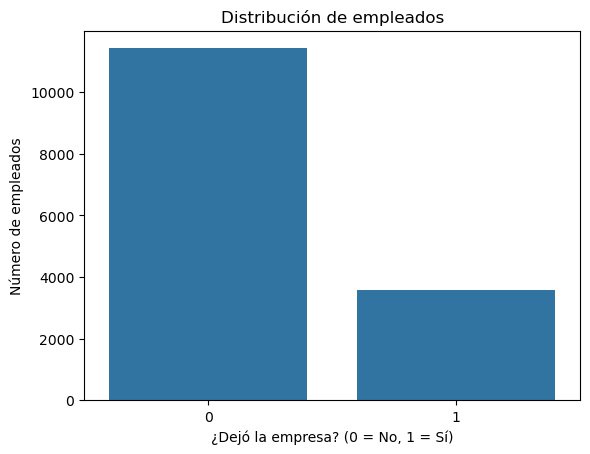

In [15]:
# Graficamos la cantidad de empleados por categoría
# Comparamos quienes dejaron la empresa con quienes permanecieron

import seaborn as sns

sns.countplot(x = "left", data = data)

plt.title("Distribución de empleados")
plt.xlabel("¿Dejó la empresa? (0 = No, 1 = Sí)")
plt.ylabel("Número de empleados")
plt.show()

In [16]:
# Aplicamos el algoritmo KNN utilizando inicialmente 3 vecinos
# Entrenamos el modelo y calculamos su precisión global

from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(x_train, y_train)

prediction = knn.predict(x_test)

print("Score: ", knn.score(x_test, y_test))

/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


Score:  0.9453333333333334


In [17]:
# Evaluamos los valores de K desde 1 hasta 20
# Calculamos la precisión global y la precisión de cada categoría
# También calculamos recall, F1-score y AUC para comparar los modelos

from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score

resultados = []

for k in range(1, 21):

    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(x_train, y_train)

    prediction = knn.predict(x_test)

    cm = confusion_matrix(y_test, prediction)

    PrecisionGlobal = knn.score(x_test, y_test)

    PrecisionNo = cm[0,0] / (cm[0,0] + cm[1,0])

    PrecisionSi = cm[1,1] / (cm[1,1] + cm[0,1])

    Recall = recall_score(y_test, prediction)

    F1 = f1_score(y_test, prediction)

    y_scores = knn.predict_proba(x_test)

    AUC = roc_auc_score(y_test, y_scores[:,1])

    resultados.append([
        k, PrecisionGlobal, PrecisionNo,
        PrecisionSi, Recall, F1, AUC
    ])

In [18]:
# Convertimos los resultados a un DataFrame
# Mostramos las métricas para los 20 valores de K

tabla = pd.DataFrame(resultados, columns=[
    "K", "Precision Global", "Precision No",
    "Precision Si", "Recall", "F1", "AUC"
])

print(tabla.round(4).to_string(index=False))

 K  Precision Global  Precision No  Precision Si  Recall     F1    AUC
 1            0.9618        0.9845        0.8958  0.9520 0.9231 0.9585
 2            0.9578        0.9689        0.9217  0.9013 0.9114 0.9644
 3            0.9453        0.9751        0.8600  0.9234 0.8906 0.9660
 4            0.9460        0.9608        0.8978  0.8755 0.8865 0.9679
 5            0.9393        0.9621        0.8690  0.8810 0.8749 0.9666
 6            0.9447        0.9597        0.8957  0.8718 0.8836 0.9664
 7            0.9411        0.9603        0.8802  0.8745 0.8774 0.9662
 8            0.9393        0.9554        0.8866  0.8579 0.8720 0.9649
 9            0.9324        0.9560        0.8585  0.8616 0.8600 0.9633
10            0.9340        0.9535        0.8709  0.8524 0.8615 0.9625
11            0.9293        0.9540        0.8520  0.8552 0.8536 0.9623
12            0.9311        0.9538        0.8590  0.8542 0.8566 0.9617
13            0.9262        0.9538        0.8412  0.8552 0.8481 0.9598
14    

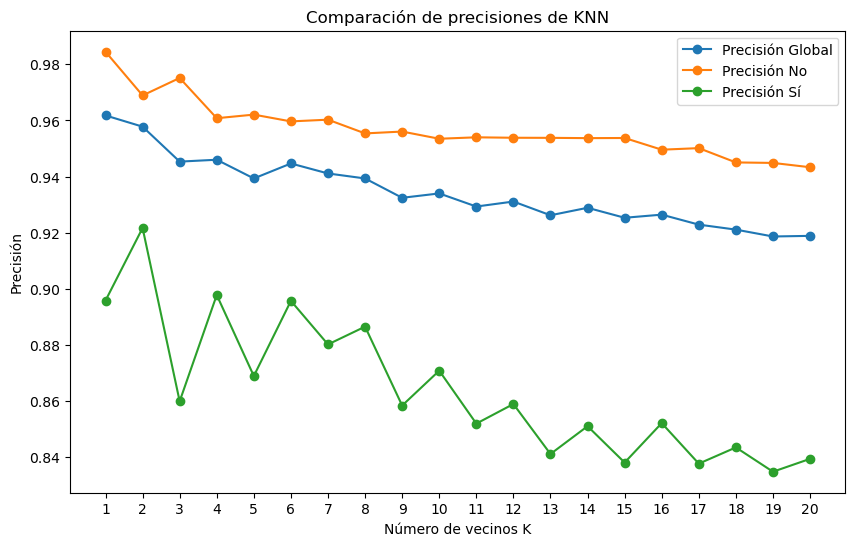

In [19]:
# Graficamos las precisiones de los distintos valores de K
# Comparamos la precisión global y las dos precisiones por categoría

plt.figure(figsize=(10,6))

plt.plot(tabla["K"], tabla["Precision Global"],
         label="Precisión Global", marker="o")

plt.plot(tabla["K"], tabla["Precision No"],
         label="Precisión No", marker="o")

plt.plot(tabla["K"], tabla["Precision Si"],
         label="Precisión Sí", marker="o")

plt.xlabel("Número de vecinos K")
plt.ylabel("Precisión")
plt.title("Comparación de precisiones de KNN")
plt.xticks(range(1,21))
plt.legend()
plt.show()

In [20]:
# Identificamos el K que obtuvo la mayor precisión global
# Mostramos sus resultados para justificar la elección

mejor_k = tabla.loc[tabla["Precision Global"].idxmax(), "K"]

print("Valor óptimo de K:", mejor_k)

print(tabla[tabla["K"] == mejor_k])

Valor óptimo de K: 1
   K  Precision Global  Precision No  Precision Si   Recall        F1      AUC
0  1          0.961778      0.984468      0.895833  0.95203  0.923077  0.95845


In [21]:
# Entrenamos el modelo definitivo utilizando el K óptimo
# Realizamos las predicciones para evaluar el modelo

knn = KNeighborsClassifier(n_neighbors=int(mejor_k))

knn.fit(x_train, y_train)

prediction = knn.predict(x_test)

print("Score: ", knn.score(x_test, y_test))

Score:  0.9617777777777777


In [22]:
# Guardamos los valores pronosticados y los valores reales
# Los utilizaremos para calcular la matriz de confusión

y_pred = prediction

y_true = y_test

In [23]:
# Calculamos la matriz de confusión del modelo KNN
# Comparamos las predicciones con los valores reales

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

cm

array([[3296,  120],
       [  52, 1032]])

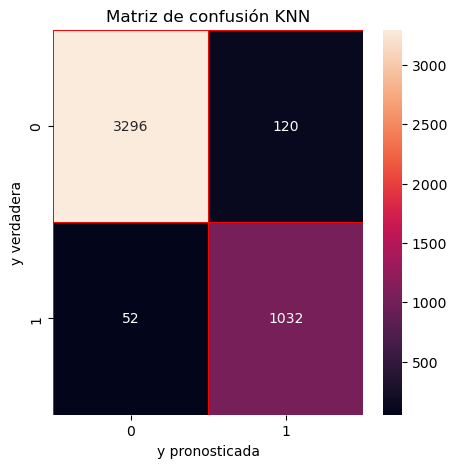

In [24]:
# Graficamos el mapa de calor de la matriz de confusión
# Mostramos los aciertos y errores del modelo

import seaborn as sns

f, ax = plt.subplots(figsize = (5,5))

sns.heatmap(cm, annot = True, linewidths = 0.5,
            linecolor = "red", fmt = ".0f", ax = ax)

plt.xlabel("y pronosticada")
plt.ylabel("y verdadera")
plt.title("Matriz de confusión KNN")
plt.show()

In [25]:
# Calculamos la cantidad de predicciones correctas e incorrectas
# Obtenemos la precisión global mediante la matriz de confusión

Correctos = cm[0,0] + cm[1,1]

Incorrectos = cm[0,1] + cm[1,0]

PrecisionGlobal = Correctos / (Correctos + Incorrectos)

print("Precisión Global:", PrecisionGlobal)

Precisión Global: 0.9617777777777777


In [26]:
# Calculamos la precisión de la categoría 0
# Empleados que no dejaron la empresa

PrecisionNo = cm[0,0] / (cm[0,0] + cm[1,0])

print("Precisión No:", PrecisionNo)

Precisión No: 0.984468339307049


In [27]:
# Calculamos la precisión de la categoría 1
# Empleados que sí dejaron la empresa

PrecisionSi = cm[1,1] / (cm[1,1] + cm[0,1])

print("Precisión Sí:", PrecisionSi)

Precisión Sí: 0.8958333333333334


In [28]:
# Importamos las funciones para calcular la curva ROC
# y el área bajo la curva AUC

from sklearn.metrics import roc_curve
from sklearn.metrics import auc

In [29]:
# Calculamos las probabilidades pronosticadas por el modelo KNN
# Utilizamos el modelo con K óptimo

y_scores = knn.predict_proba(x_test)

print(y_scores)

[[1. 0.]
 [1. 0.]
 [1. 0.]
 ...
 [1. 0.]
 [1. 0.]
 [0. 1.]]


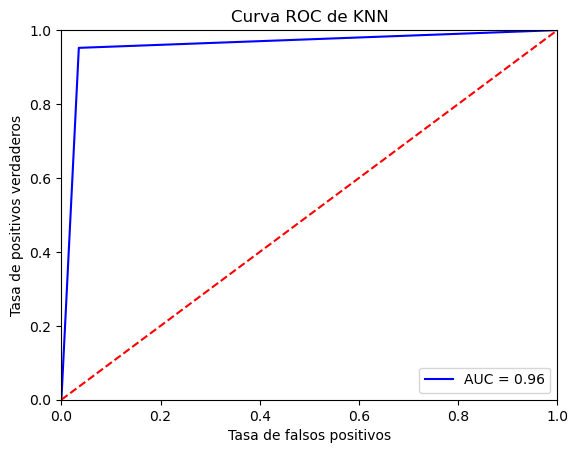

In [30]:
# Calculamos la curva ROC y el área bajo la curva
# Evaluamos la capacidad del modelo para identificar empleados
# que abandonaron la empresa

fpr, tpr, threshold = roc_curve(y_test, y_scores[:,1])

# fpr = False positive rate, tpr = True positive rate
roc_auc = auc(fpr, tpr)

plt.title('Receiver Operating Characteristic')

plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)

plt.legend(loc = 'lower right')

plt.plot([0,1], [0,1], 'r--')

plt.xlim([0,1])
plt.ylim([0,1])

plt.ylabel("Tasa de positivos verdaderos")
plt.xlabel("Tasa de falsos positivos")

plt.title("Curva ROC de KNN")
plt.show()